<a href="https://colab.research.google.com/github/ML-HW-SYS/a2-AaronGoldblatt/blob/main/6_pruning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **6. Model Pruning**

## 6.0 Setup GDrive and Git

In [1]:
# Mount google drive
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
# Make sure your token is stored in a txt file at the location below.
# This way there is no risk that you will push it to your repo
# Never share your token with anyone, it is basically your github password!
with open('/content/gdrive/MyDrive/ece5545/token.txt') as f:
    token = f.readline().strip()
# Use another file to store your github username
with open('/content/gdrive/MyDrive/ece5545/git_username.txt') as f:
    handle = f.readline().strip()

In [5]:
# Clone your github repo
YOUR_TOKEN = token
YOUR_HANDLE = handle
BRANCH = "main"

%mkdir /content/gdrive/MyDrive/ece5545
%cd /content/gdrive/MyDrive/ece5545
!git clone https://{YOUR_TOKEN}@github.com/ML-HW-SYS/a2-{YOUR_HANDLE}.git
%cd /content/gdrive/MyDrive/ece5545/a2-{YOUR_HANDLE}
!git checkout {BRANCH}
!git pull
%cd /content/gdrive/MyDrive/ece5545

PROJECT_ROOT = f"/content/gdrive/MyDrive/ece5545/a2-{YOUR_HANDLE}"

mkdir: cannot create directory ‘/content/gdrive/MyDrive/ece5545’: File exists
/content/gdrive/MyDrive/ece5545
fatal: destination path 'a2-AaronGoldblatt' already exists and is not an empty directory.
/content/gdrive/MyDrive/ece5545/a2-AaronGoldblatt
Already on 'main'
Your branch is up to date with 'origin/main'.
Already up to date.
/content/gdrive/MyDrive/ece5545


In [6]:
# This extension reloads all imports before running each cell
%load_ext autoreload
%autoreload 2

### GPU: Ensure you are running the GPU runtime type:
1.   Click "Runtime" on top banner
2.   Select "Change runtime type"
3.   Under "Hardware accelarator" select "GPU" and save

### Install required packages

In [7]:
!pip install torchaudio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 86.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 89.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

### Import code dependencies

In [8]:
# Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.nn.utils.prune as prune

import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import numpy as np
import copy

import time

import sys

# Adding assignment1 to the system path-- make sure this matches your git directory
sys.path.insert(0, PROJECT_ROOT)

# Import data_proc to use data processing functions
import src.data_proc as data_proc

# Import constants to use constants defined for training
from src.constants import *

# TensorBoard
from torch.utils.tensorboard import SummaryWriter

# Set random seed
# Make sure the shuffling and picking is deterministic
# Note that different value of random_seed may change rate of variation in loss/accuracy during training
# Using the same random seed value every time you rerun the notebook will
# reproduce the training and testing results
random_seed = 0
torch.manual_seed(random_seed)
torch.cuda.manual_seed(random_seed)

Model folders are created, 
PyTorch models will be saved in /content/gdrive/MyDrive/ece5545/models/torch_models, 
ONNX models will be saved in /content/gdrive/MyDrive/ece5545/models/onnx_models, 
TensorFlow Saved Models will be saved in /content/gdrive/MyDrive/ece5545/models/tf_models, 
TensorFlow Lite models will be saved in /content/gdrive/MyDrive/ece5545/models/tflite_models, 
TensorFlow Lite Micro models will be saved in /content/gdrive/MyDrive/ece5545/models/micro_models.


## 6.1 Prepare for Training



In [9]:
# Create audio_processor
# DATASET_DIR is defined in constants.py
audio_processor = data_proc.AudioProcessor()
print("Audio_processor created")

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Using {device} to run the training scrpit.')

# Define data loaders
from src.loaders import make_data_loaders
data_loaders = make_data_loaders(audio_processor, device)
train_loader = data_loaders['training']
test_loader = data_loaders['testing']
valid_loader = data_loaders['validation']

# Create a full precision (float32) TinyConv model
from src.networks import TinyConv
model_fp32 = TinyConv(model_settings=audio_processor.model_settings, \
    n_input=1, n_output=audio_processor.num_labels)

model_fp32

>> Downloading speech_commands_v0.02.tar.gz 100.0%
Audio_processor created
Using cuda to run the training scrpit.
Train size: 10556 Val size: 1333 Test size: 1368


TinyConv(
  (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
  (conv): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc_reshape): Reshape(output_shape=(-1, 4000))
  (fc): Linear(in_features=4000, out_features=4, bias=True)
  (softmax): Softmax(dim=1)
)

In [10]:
!ls {TORCH_DIR}

fp32_checkpoint.pt		 quant_checkpoint.pt
fp32_checkpoint.pt.old		 quant_checkpoint.pt.old
fp32_finetune_checkpoint.pt	 tinyconv_float32_init_seed0_92.25%_0.pt
fp32_finetune_checkpoint.pt.old


### **TODO: Replace the torch_path model with the model you created in the last section.**

You can find the name of your file in `TORCH_DIR` under the folder icon to the left. (Or from running the tab above).

In [11]:
# TODO: Replace me!
torch_path = os.path.join(TORCH_DIR, "tinyconv_float32_init_seed0_92.25%_0.pt")

# Load model
model_fp32.load_state_dict(torch.load(torch_path))
model_fp32_orig = copy.deepcopy(model_fp32)
model_fp32, model_fp32_orig

<ipython-input-11-d99b6118d8e5>:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_fp32.load_state_dict(torch.load(torch_path))


(TinyConv(
   (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
   (conv): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
   (relu): ReLU()
   (dropout): Dropout(p=0.5, inplace=False)
   (fc_reshape): Reshape(output_shape=(-1, 4000))
   (fc): Linear(in_features=4000, out_features=4, bias=True)
   (softmax): Softmax(dim=1)
 ),
 TinyConv(
   (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
   (conv): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
   (relu): ReLU()
   (dropout): Dropout(p=0.5, inplace=False)
   (fc_reshape): Reshape(output_shape=(-1, 4000))
   (fc): Linear(in_features=4000, out_features=4, bias=True)
   (softmax): Softmax(dim=1)
 ))

In [12]:
pruning_thresholds = [
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    0.95,
]

## 6.2 Structured Pruning

In this section, you will try to conduct structured pruning on the TinyConv model and explore its effect on performance.
In this notebook, you will be only given minimum scarfolding code. Please take advantages of the code in previous section to faciliate.

Following link will be helpful:
[torch.nn.utils.prune.LnStructured](https://pytorch.org/docs/stable/generated/torch.nn.utils.prune.LnStructured.html?highlight=prune#torch.nn.utils.prune.LnStructured.prune)
[Torch pruning tutorial](https://pytorch.org/tutorials/intermediate/pruning_tutorial.html?highlight=prune)

In [13]:
def structured_pruning(model, threshold, norm_type=1):
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            prune.ln_structured(module, name="weight", n=norm_type, amount=threshold, dim=0)
            prune.remove(module, "weight")
        elif isinstance(module, nn.Linear):
            # Use dim=1 to prune only input connections to ensure that network doesn't become disconnected and that an output class isn't removed
            prune.ln_structured(module, name="weight", n=norm_type, amount=threshold, dim=1)
            prune.remove(module, "weight")
    return model

In [31]:
structured_pruning_results = {
    'pruned_models': [],
    'finetuned_pruned_models': [],
    'thresholds': [],
    'num_params': [],
    'flops': [],
    'base_accs': [],
    'finetuned_accs': [],
    'cpu_runtimes': [],
    'mcu_runtimes': [],
}

In [27]:
def count_nonzero_params(model):
    conv_params = (
        model.conv.weight.nelement()
        - torch.sum(model.conv.weight == 0)
        + model.conv.bias.nelement()
    )
    linear_params = (
        model.fc.weight.nelement()
        - torch.sum(model.fc.weight == 0)
        + model.fc.bias.nelement()
    )
    return float(conv_params + linear_params)

In [32]:
from src.size_estimate import flop
from src.train_val_test_utils import test

for threshold in pruning_thresholds:
    structured_pruning_results['thresholds'].append(threshold)
    model = copy.deepcopy(model_fp32)
    pruned_model = structured_pruning(model, threshold)
    structured_pruning_results['pruned_models'].append(pruned_model)
    pruned_model.to(device)

    num_params = count_nonzero_params(pruned_model)
    structured_pruning_results['num_params'].append(num_params)

    flop_by_layers = flop(
        model=pruned_model,
        input_shape=(
            1,
            model_fp32.model_settings['fingerprint_width'],
            model_fp32.model_settings['spectrogram_length']
        ),
        device=device
    )
    total_param_flops = sum([sum(val.values()) for val in flop_by_layers.values()])
    structured_pruning_results['flops'].append(total_param_flops)

    base_acc = test(
        test_loader,
        model,
        device,
        loader_type='Test'
    )
    structured_pruning_results['base_accs'].append(base_acc)

In [37]:
def plot_accuracy_vs_parameters(results, acc_type='base_accs', pruning_type='Structured', save_path=None):
    """
    Plot accuracy vs parameters for pruning results.

    Args:
        results: Dictionary containing 'params', 'thresholds', and either 'base_accs' or 'finetuned_accs'
        acc_type: String indicating which accuracy to plot ('base_accs' or 'finetuned_accs')
        pruning_type: String indicating type of pruning ('Structured' or 'Unstructured')
        save_path: Optional path to save the plot (e.g., 'accuracy_vs_params.png')
    """
    plt.figure(figsize=(10, 6))

    # Select correct accuracy data and title suffix
    if acc_type == 'base_accs':
        acc_data = results['base_accs']
        title_suffix = 'without Fine-tuning'
        color = 'blue'
    elif acc_type == 'finetuned_accs':
        acc_data = results['finetuned_accs']
        title_suffix = 'with Fine-tuning'
        color = 'red'
    else:
        raise ValueError(f"Invalid accuracy type: {acc_type}")

    # Plot accuracy vs parameters
    plt.plot(results['num_params'],
         acc_data,
         'o--',  # Only specify marker and line style here
         color=color,  # Specify color separately
         linewidth=2,
         markersize=8)

    # Add threshold labels to points
    for i, (param, acc, threshold) in enumerate(zip(results['num_params'],
                                                   acc_data,
                                                   results['thresholds'])):
        plt.annotate(f'{threshold:.2f}',  # threshold value with 1 decimal
                    (param, acc),
                    xytext=(10, 10),      # offset from point
                    textcoords='offset points',
                    fontsize=10,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

    # Add labels and title
    plt.xlabel('Number of Parameters', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.title(f'Accuracy vs. Number of Parameters ({pruning_type} Pruning, {title_suffix})', fontsize=14)

    # Add grid
    plt.grid(True, linestyle='--', alpha=0.7)

    # Adjust layout to prevent label cutoff
    plt.tight_layout()

    # Save if path provided
    if save_path:
        plt.savefig(save_path)

    plt.show()

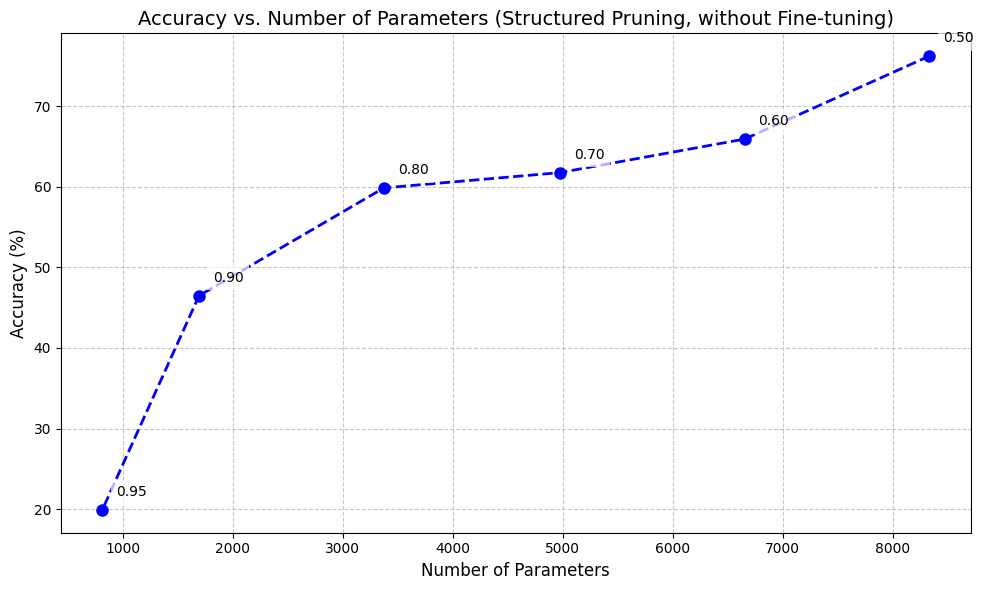

In [38]:
plot_accuracy_vs_parameters(
    structured_pruning_results,
    acc_type='base_accs',
    pruning_type='Structured'
)

In [41]:
def plot_accuracy_vs_flops(results, acc_type='base_accs', save_path=None):
    """
    Plot accuracy vs FLOPs for structured pruning results.

    Args:
        results: Dictionary containing 'flops', 'thresholds', and either 'base_accs' or 'finetuned_accs'
        acc_type: String indicating which accuracy to plot ('base_accs' or 'finetuned_accs')
        save_path: Optional path to save the plot
    """
    plt.figure(figsize=(10, 6))

    # Select correct accuracy data and title suffix
    if acc_type == 'base_accs':
        acc_data = results['base_accs']
        title_suffix = 'without Fine-tuning'
        color = 'blue'
    elif acc_type == 'finetuned_accs':
        acc_data = results['finetuned_accs']
        title_suffix = 'with Fine-tuning'
        color = 'red'
    else:
        raise ValueError(f"Invalid accuracy type: {acc_type}")

    # Plot accuracy vs FLOPs
    plt.plot(results['flops'],
             acc_data,
             'o--',
             color=color,
             linewidth=2,
             markersize=8)

    # Add threshold labels to points
    for i, (flop, acc, threshold) in enumerate(zip(results['flops'],
                                                  acc_data,
                                                  results['thresholds'])):
        plt.annotate(f'{threshold:.2f}',
                    (flop, acc),
                    xytext=(10, 10),
                    textcoords='offset points',
                    fontsize=10,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

    # Add labels and title
    plt.xlabel('FLOPs', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.title(f'Accuracy vs FLOPs (Structured Pruning, {title_suffix})', fontsize=14)

    # Add grid
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)

    plt.show()

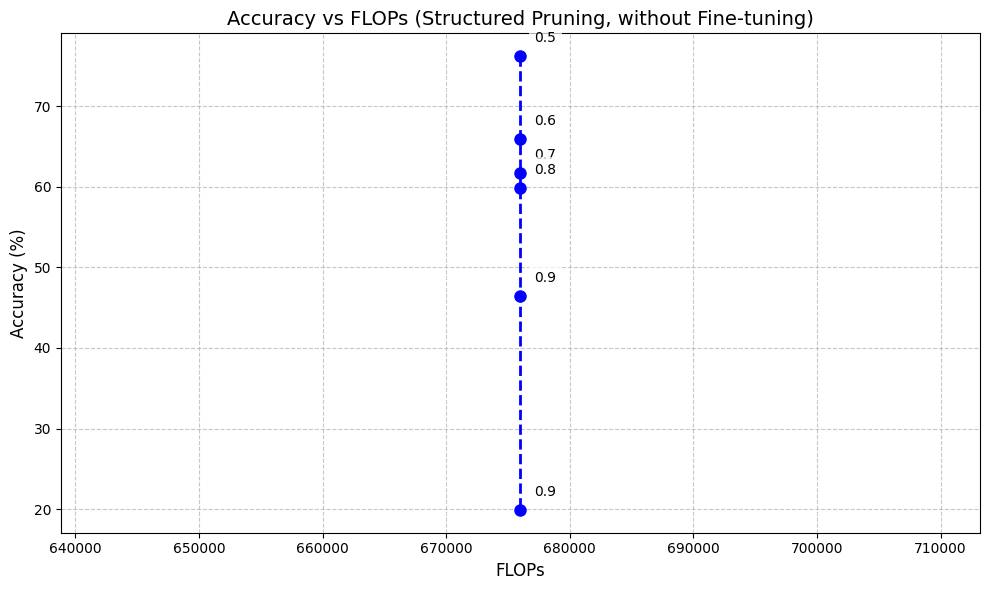

In [42]:
plot_accuracy_vs_flops(
    structured_pruning_results,
    acc_type='base_accs',
)

In [ ]:
from src.train_val_test_utils import create_optimizer, train, test

def fine_tune(model, device, epochs=10, learning_rate=0.001):
    optimizer = create_optimizer(model, learning_rate=learning_rate)
    best_acc = 0
    best_model = None
    for epoch in range(1, epochs + 1):
        train(
            model,
            data_loaders,
            optimizer,
            epoch,
            device
        )
        val_acc = test(
            valid_loader,
            model,
            device,
            epoch=epoch,
            loader_type='Valid'
        )
        if val_acc > best_acc:
            best_acc = val_acc
            best_model = copy.deepcopy(model.state_dict())
    if best_model is not None:
        model.load_state_dict(best_model)
    test_acc = test(
        test_loader,
        model,
        device,
        loader_type='Test'
    )
    return model, test_acc

In [ ]:
for idx, model in enumerate(structured_pruning_results['pruned_models']):
    finetuned_model, finetuned_acc = fine_tune(model, data_loaders, device)
    structured_pruning_results['finetuned_pruned_models'].append(finetuned_model)
    structured_pruning_results['finetuned_accs'].append(finetuned_acc)

In [ ]:
plot_accuracy_vs_parameters(
    structured_pruning_results,
    acc_type='finetuned_accs',
    pruning_type='Structured'
)

In [ ]:
def measure_cpu_runtime(model):
    model = model.cpu()
    model.eval()
    inputs = torch.rand([1, 1960]).cpu()
    with profile(activities=[ProfilerActivity.CPU], record_shapes=True) as prof:
        with record_function("model_inference"):
            model(inputs)
    return prof.key_averages().self_cpu_time_total

In [ ]:
for model in structured_pruning_results['finetuned_pruned_models']:
    cpu_runtime = measure_cpu_runtime(model)
    structured_pruning_results['cpu_runtimes'].append(cpu_runtime)

In [ ]:
def plot_accuracy_vs_runtime(results, runtime_type='CPU', save_path=None):
    """
    Plot accuracy vs runtime for structured pruning results.

    Args:
        results: Dictionary containing 'cpu_runtime' or 'mcu_runtime', 'thresholds', and 'finetuned_accs'
        runtime_type: String indicating which runtime to plot ('CPU' or 'MCU')
        save_path: Optional path to save the plot
    """
    plt.figure(figsize=(10, 6))

    # Select correct runtime data
    if runtime_type == 'CPU':
        runtime_data = results['cpu_runtime']
        xlabel = 'CPU Runtime (ms)'
    elif runtime_type == 'MCU':
        runtime_data = results['mcu_runtime']
        xlabel = 'MCU Runtime (ms)'
    else:
        raise ValueError(f"Invalid runtime type: {runtime_type}")

    # Plot accuracy vs runtime (always using finetuned accuracy)
    plt.plot(runtime_data,
             results['finetuned_accs'],
             'ro--',  # red dots with dashed line
             linewidth=2,
             markersize=8)

    # Add threshold labels to points
    for i, (runtime, acc, threshold) in enumerate(zip(runtime_data,
                                                     results['finetuned_accs'],
                                                     results['thresholds'])):
        plt.annotate(f'{threshold:.1f}',
                    (runtime, acc),
                    xytext=(10, 10),
                    textcoords='offset points',
                    fontsize=10,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

    # Add labels and title
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.title(f'Accuracy vs {runtime_type} Runtime (Structured Pruning)', fontsize=14)

    # Add grid
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)

    plt.show()

In [ ]:
plot_accuracy_vs_runtime(
    structured_pruning_results,
    runtime_type='CPU'
)

In [ ]:
# Obtained MCU runtimes by running the 5 finetuned structured pruning models on the MCU
structured_pruning_results['mcu_runtimes'] = [
    # Threshold 0.5
    0,
    # Threshold 0.6
    0,
    # Threshold 0.7
    0,
    # Threshold 0.8
    0,
    # Threshold 0.9
    0,
    # Threshold 0.95
    0,
]

In [ ]:
plot_accuracy_vs_runtime(
    structured_pruning_results,
    runtime_type='MCU'
)

In [ ]:
import os

# Save the finetuned structured pruning models
def save_finetuned_models(results, pruning_type='structured', torch_dir=TORCH_DIR):
    for idx, model in enumerate(results['finetuned_pruned_models']):
        threshold = results['thresholds'][idx]
        model_path = os.path.join(
            torch_dir,
            f'finetuned_{pruning_type}_pruning_model_threshold_{threshold}.pt'
        )
        torch.save(
            model.state_dict(),
            model_path
        )
        print(f"Saved {pruning_type} pruned model with threshold {threshold} to {model_path}")

In [ ]:
save_finetuned_models(structured_pruning_results, pruning_type='structured')

## 6.3 Unstructured Pruning

In this section, you will perform unstructured pruning on the TinyConv model and explore its effect on performance.

Following link will be helpful:
1. [torch.nn.utils.prune.l1_unstructured](https://pytorch.org/docs/stable/generated/torch.nn.utils.prune.l1_unstructured.html?highlight=unstructured#torch.nn.utils.prune.l1_unstructured)

2. [torch.nn.utils.prune.random_unstructured](https://pytorch.org/docs/stable/generated/torch.nn.utils.prune.random_unstructured.html?highlight=unstructured#torch.nn.utils.prune.random_unstructured)

2. [Torch pruning tutorial](https://pytorch.org/tutorials/intermediate/pruning_tutorial.html?highlight=prune)

In [ ]:
def unstructured_pruning(model, threshold):
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d) or isinstance(module, nn.Linear):
            prune.l1_unstructured(module, name='weight', amount=threshold)
            prune.remove(module, 'weight')
    return model

In [ ]:
unstructured_pruning_results = {
    'pruned_models': [],
    'finetuned_pruned_models': [],
    'thresholds': [],
    'num_params': [],
    'base_accs': [],
    'finetuned_accs': [],
}

In [ ]:
for threshold in pruning_thresholds:
    unstructured_pruning_results['thresholds'].append(threshold)
    model = copy.deepcopy(model_fp32)
    pruned_model = unstructured_pruning(model, threshold)
    unstructured_pruning_results['pruned_models'].append(pruned_model)
    pruned_model.to(device)

    num_params = count_nonzero_params(pruned_model)
    unstructured_pruning_results['num_params'].append(num_params)

    base_acc = test(
        test_loader,
        pruned_model,
        device,
        loader_type='Test'
    )
    unstructured_pruning_results['base_accs'].append(base_acc)

In [ ]:
plot_accuracy_vs_parameters(
    unstructured_pruning_results,
    acc_type='base_accs',
    pruning_type='Unstructured'
)

In [ ]:
for idx, model in enumerate(unstructured_pruning_results['pruned_models']):
    finetuned_model, finetuned_acc = fine_tune(model, data_loaders, device)
    unstructured_pruning_results['finetuned_pruned_models'].append(finetuned_model)
    unstructured_pruning_results['finetuned_accs'].append(finetuned_acc)

In [ ]:
plot_accuracy_vs_parameters(
    unstructured_pruning_results,
    acc_type='finetuned_accs',
    pruning_type='Unstructured'
)

In [ ]:
save_finetuned_models(unstructured_pruning_results, pruning_type='unstructured')